# 05 独立测试与跨场景泛化评价

完成 E1—E3 并用验证集选定 E3 后，统一评价 **PlantVillage 独立测试集**与**去重后的 PlantDoc 外部集合**。同时分别报告 PlantDoc `train` 来源与 `test` 来源的结果，来源名称不表示本项目训练用途。

默认 `RUN_EVALUATION=False`。评价只用于最终报告，不再依据测试结果调整模型或超参数。指标至少包括 Accuracy、Macro Precision、Macro Recall、Macro-F1、逐类 Precision / Recall / F1 和混淆矩阵，训练耗时读取实际记录。


In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


def find_project_root():
    current = Path.cwd().resolve()
    for candidate in (current, *current.parents):
        for root in (candidate, candidate / "plant-disease-project"):
            if (root / "configs" / "base.yaml").is_file():
                return root
    raise FileNotFoundError("请在项目根目录或 notebooks 目录打开本 Notebook。")


PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.utils import load_config, load_labels

BASE = load_config(PROJECT_ROOT / "configs" / "base.yaml")
EXPERIMENTS = load_config(PROJECT_ROOT / "configs" / "experiments.yaml")
LABELS = load_config(PROJECT_ROOT / "configs" / "labels.yaml")
CLASS_NAMES = [item["label"] for item in load_labels(PROJECT_ROOT)]
assert len(CLASS_NAMES) == 8 and len(set(CLASS_NAMES)) == 8
assert [item["label_index"] for item in LABELS["classes"]] == list(range(8))
print("项目目录：", PROJECT_ROOT)
print("类别数量：", len(CLASS_NAMES), "；随机种子：", BASE["seed"])


项目目录： /Users/qingjiarui/Desktop/深度学习课程作业/基于迁移学习的植物叶片病害识别与真实场景泛化优化研究/plant-disease-project
类别数量： 8 ；随机种子： 42


## 1. 确认最终模型并运行评价

最终模型由保存的 `selected_runs.e3` 解析，函数重新检查正式完成状态、八类顺序、当前配置和清单指纹。未训练时只提示前置工作。确认后将 `RUN_EVALUATION=True` 并运行本格；不需要手工寻找或填写旧实验目录。


In [3]:
from src.experiments import selected_run
from src.evaluate import evaluate_final

RUN_EVALUATION = True
final_run = None
try:
    final_run = selected_run(PROJECT_ROOT, "E3")
    print("最终实验：", final_run.name)
except (ValueError, FileNotFoundError) as error:
    print("请完成 02—04 并保存 E3 选择：", error)

if RUN_EVALUATION and final_run is not None:
    evaluate_final(PROJECT_ROOT)
    print("评价结果已保存：", final_run / "metrics.json")
elif not RUN_EVALUATION:
    print("评价关闭：如已完成，可在后续单元加载保存结果。")


最终实验： e3_efficientnet_b0_full_combined_s42_20261021T065510_c05233
评价结果已保存： /Users/qingjiarui/Desktop/深度学习课程作业/基于迁移学习的植物叶片病害识别与真实场景泛化优化研究/plant-disease-project/outputs/runs/e3_efficientnet_b0_full_combined_s42_20261021T065510_c05233/metrics.json


## 2. 汇总真实指标与跨场景差值

分别展示 PlantDoc 两个来源及整体结果。来源分组已在整体去重后保留，不能将原始 675 + 69 张直接当作有效评价数。差值定义为“PlantVillage 减 PlantDoc”；类别分布不同、样本量较小和潜在标签噪声都可能影响差值。


In [4]:
metrics = {}
if final_run is not None and (final_run / "metrics.json").is_file():
    metrics = load_config(final_run / "metrics.json")
pv = metrics.get("plantvillage_test")
pd_external = metrics.get("plantdoc_external_all")
evaluation_sets = {}
if pv:
    evaluation_sets["plantvillage_test"] = pv
if pd_external:
    evaluation_sets["plantdoc_external_all"] = pd_external
    for source_name, source_metrics in pd_external.get("source_splits", {}).items():
        evaluation_sets[f"plantdoc_{source_name}_source"] = source_metrics

summary_rows = []
for dataset_name, result in evaluation_sets.items():
    macro = result["classification_report"]["macro avg"]
    summary_rows.append({"dataset": dataset_name, "samples": result["sample_count"],
                         "accuracy": result["accuracy"], "macro_precision": macro["precision"],
                         "macro_recall": macro["recall"], "macro_f1": result["macro_f1"]})
if not summary_rows:
    print("尚无最终八分类测试结果；不显示旧结果或模拟指标。")
else:
    summary_table = pd.DataFrame(summary_rows)
    display(summary_table)
    table_dir = PROJECT_ROOT / "outputs" / "tables"
    table_dir.mkdir(parents=True, exist_ok=True)
    summary_table.to_csv(table_dir / "cross_domain_comparison.csv", index=False, encoding="utf-8-sig")
    if pv and pd_external:
        print("Accuracy 差值：", pv["accuracy"] - pd_external["accuracy"])
        print("Macro-F1 差值：", pv["macro_f1"] - pd_external["macro_f1"])
    print("训练状态与耗时记录：", final_run / "status.json", final_run / "history.csv")


,dataset,samples,accuracy,macro_precision,macro_recall,macro_f1
0,plantvillage_test,2259,0.992475,0.981837,0.991158,0.986161
1,plantdoc_external_all,629,0.294118,0.283092,0.240280,0.173770
2,plantdoc_test_source,60,0.283333,0.108877,0.240972,0.148259
3,plantdoc_train_source,569,0.295255,0.304147,0.240728,0.176209


Accuracy 差值： 0.6983568992005833
Macro-F1 差值： 0.8123912417167876
训练状态与耗时记录： /Users/qingjiarui/Desktop/深度学习课程作业/基于迁移学习的植物叶片病害识别与真实场景泛化优化研究/plant-disease-project/outputs/runs/e3_efficientnet_b0_full_combined_s42_20261021T065510_c05233/status.json /Users/qingjiarui/Desktop/深度学习课程作业/基于迁移学习的植物叶片病害识别与真实场景泛化优化研究/plant-disease-project/outputs/runs/e3_efficientnet_b0_full_combined_s42_20261021T065510_c05233/history.csv


## 3. 逐类指标与混淆矩阵

混淆矩阵行是真实类别，列是预测类别，编号与标签配置相同。没有真实样本的类别仍保留位置，零支持类别的 Precision / Recall / F1 不能视为稳定能力估计。所有表格、图均来自刚读取的实际指标。


plantvillage_test


,label_index,label,precision,recall,f1-score,support
0,0,tomato_bacterial_spot,1.000000,0.996865,0.998430,319.0
1,1,tomato_early_blight,0.979866,0.979866,0.979866,149.0
2,2,tomato_late_blight,0.992883,0.978947,0.985866,285.0
3,3,tomato_leaf_mold,0.986301,1.000000,0.993103,144.0
4,4,tomato_septoria_leaf_spot,0.996139,0.973585,0.984733,265.0
5,5,tomato_tomato_mosaic_virus,0.903226,1.000000,0.949153,56.0
6,6,tomato_tomato_yellow_leaf_curl_virus,0.996278,1.000000,0.998135,803.0
7,7,tomato_healthy,1.000000,1.000000,1.000000,238.0


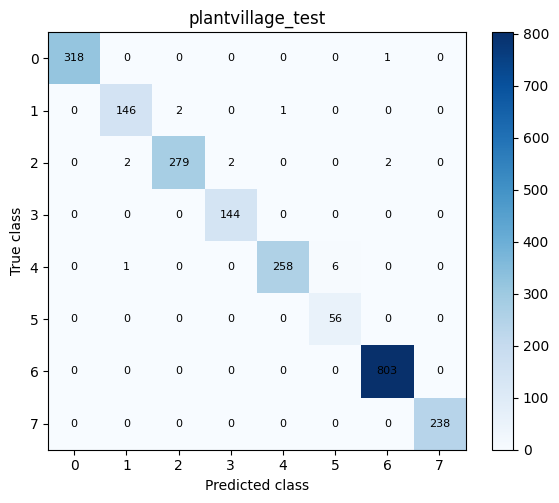

plantdoc_external_all


,label_index,label,precision,recall,f1-score,support
0,0,tomato_bacterial_spot,0.333333,0.013699,0.026316,73.0
1,1,tomato_early_blight,0.210046,0.605263,0.311864,76.0
2,2,tomato_late_blight,0.335079,0.627451,0.436860,102.0
3,3,tomato_leaf_mold,0.000000,0.000000,0.000000,73.0
4,4,tomato_septoria_leaf_spot,0.341837,0.572650,0.428115,117.0
5,5,tomato_tomato_mosaic_virus,0.000000,0.000000,0.000000,53.0
6,6,tomato_tomato_yellow_leaf_curl_virus,0.444444,0.055556,0.098765,72.0
7,7,tomato_healthy,0.600000,0.047619,0.088235,63.0


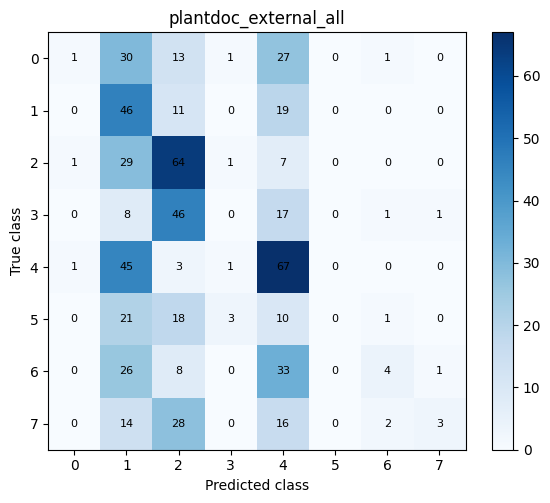

plantdoc_test_source


,label_index,label,precision,recall,f1-score,support
0,0,tomato_bacterial_spot,0.000000,0.000000,0.000000,5.0
1,1,tomato_early_blight,0.300000,0.750000,0.428571,8.0
2,2,tomato_late_blight,0.266667,0.400000,0.320000,10.0
3,3,tomato_leaf_mold,0.000000,0.000000,0.000000,4.0
4,4,tomato_septoria_leaf_spot,0.304348,0.777778,0.437500,9.0
5,5,tomato_tomato_mosaic_virus,0.000000,0.000000,0.000000,10.0
6,6,tomato_tomato_yellow_leaf_curl_virus,0.000000,0.000000,0.000000,6.0
7,7,tomato_healthy,0.000000,0.000000,0.000000,8.0


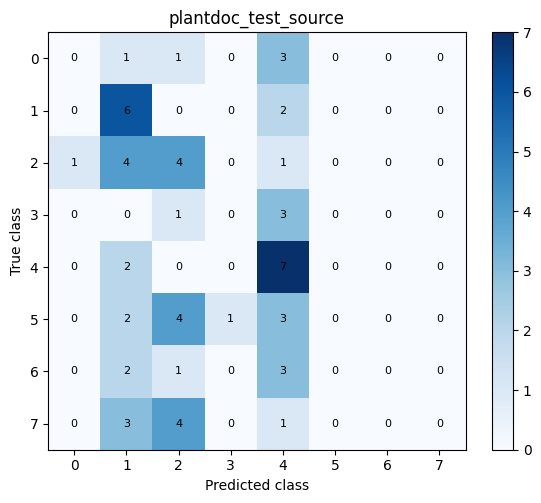

plantdoc_train_source


,label_index,label,precision,recall,f1-score,support
0,0,tomato_bacterial_spot,0.500000,0.014706,0.028571,68.0
1,1,tomato_early_blight,0.201005,0.588235,0.299625,68.0
2,2,tomato_late_blight,0.340909,0.652174,0.447761,92.0
3,3,tomato_leaf_mold,0.000000,0.000000,0.000000,69.0
4,4,tomato_septoria_leaf_spot,0.346821,0.555556,0.427046,108.0
5,5,tomato_tomato_mosaic_virus,0.000000,0.000000,0.000000,43.0
6,6,tomato_tomato_yellow_leaf_curl_virus,0.444444,0.060606,0.106667,66.0
7,7,tomato_healthy,0.600000,0.054545,0.100000,55.0


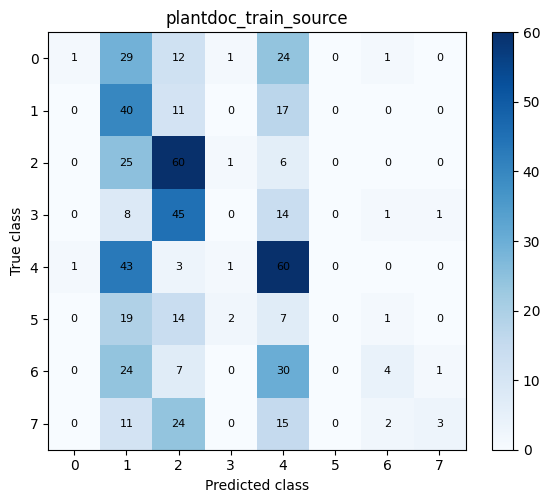

In [5]:
if not evaluation_sets:
    print("尚无逐类指标。")
else:
    import numpy as np
    figure_dir = PROJECT_ROOT / "outputs" / "figures" / final_run.name
    figure_dir.mkdir(parents=True, exist_ok=True)
    for dataset_name, result in evaluation_sets.items():
        class_rows = [{"label_index": index, "label": label,
                       **result["classification_report"][label]}
                      for index, label in enumerate(CLASS_NAMES)]
        print(dataset_name)
        class_table = pd.DataFrame(class_rows)
        display(class_table)
        class_table.to_csv(PROJECT_ROOT / "outputs" / "tables" / f"{dataset_name}_per_class.csv",
                           index=False, encoding="utf-8-sig")
        matrix = np.asarray(result["confusion_matrix"])
        fig, axis = plt.subplots(figsize=(6, 5))
        plot = axis.imshow(matrix, cmap="Blues")
        axis.set(xticks=range(8), yticks=range(8), xlabel="Predicted class", ylabel="True class",
                 title=dataset_name)
        for row in range(8):
            for column in range(8):
                axis.text(column, row, str(matrix[row, column]), ha="center", va="center", fontsize=8)
        fig.colorbar(plot, ax=axis)
        fig.tight_layout()
        fig.savefig(figure_dir / f"{dataset_name}_confusion_matrix.png", dpi=160)
        plt.show()


## 4. 各类别错误分析

错误表包含每个数据集和真实类别的样本数、错误数、错误率与最常见误判类别；示例来自保存的逐图预测，不据此重新调参。优先结合光照、遮挡、复杂背景、相似病斑和潜在标签错误讨论原因。


In [6]:
if final_run is None or not (final_run / "predictions.csv").is_file():
    print("尚无逐图预测记录。")
else:
    predictions = pd.read_csv(final_run / "predictions.csv")
    predictions["is_error"] = predictions["true_label"] != predictions["predicted_label"]
    error_rows = []
    for (dataset_name, label), group in predictions.groupby(["dataset", "true_label"], sort=False):
        wrong = group[group["is_error"]]
        error_rows.append({"dataset": dataset_name, "true_label": label, "samples": len(group),
                           "errors": len(wrong), "error_rate": len(wrong) / len(group),
                           "most_confused_with": wrong["predicted_label"].mode().iloc[0] if len(wrong) else ""})
    error_table = pd.DataFrame(error_rows)
    display(error_table)
    error_table.to_csv(PROJECT_ROOT / "outputs" / "tables" / "per_class_error_analysis.csv",
                       index=False, encoding="utf-8-sig")
    display(predictions[predictions["is_error"]].groupby(["dataset", "true_label"], sort=False).head(2))


,dataset,true_label,samples,errors,error_rate,most_confused_with
0,plantvillage_test,tomato_bacterial_spot,319,1,0.003135,tomato_tomato_yellow_leaf_curl_virus
1,plantvillage_test,tomato_early_blight,149,3,0.020134,tomato_late_blight
2,plantvillage_test,tomato_late_blight,285,6,0.021053,tomato_early_blight
3,plantvillage_test,tomato_leaf_mold,144,0,0.000000,
4,plantvillage_test,tomato_septoria_leaf_spot,265,7,0.026415,tomato_tomato_mosaic_virus
5,plantvillage_test,tomato_tomato_mosaic_virus,56,0,0.000000,
6,plantvillage_test,tomato_tomato_yellow_leaf_curl_virus,803,0,0.000000,
7,plantvillage_test,tomato_healthy,238,0,0.000000,
8,plantdoc_external_all,tomato_bacterial_spot,73,72,0.986301,tomato_early_blight
9,plantdoc_external_all,tomato_early_blight,76,30,0.394737,tomato_septoria_leaf_spot


,dataset,image_path,original_split,true_label,true_index,predicted_label,predicted_index,confidence,correct,is_error
83,plantvillage_test,data/plantvillage/color/tomato_bacterial_spot/...,color,tomato_bacterial_spot,0,tomato_tomato_yellow_leaf_curl_virus,6,0.890121,False,True
420,plantvillage_test,data/plantvillage/color/tomato_early_blight/pv...,color,tomato_early_blight,1,tomato_late_blight,2,0.525112,False,True
442,plantvillage_test,data/plantvillage/color/tomato_early_blight/pv...,color,tomato_early_blight,1,tomato_septoria_leaf_spot,4,0.950449,False,True
504,plantvillage_test,data/plantvillage/color/tomato_late_blight/pv_...,color,tomato_late_blight,2,tomato_early_blight,1,0.770741,False,True
529,plantvillage_test,data/plantvillage/color/tomato_late_blight/pv_...,color,tomato_late_blight,2,tomato_leaf_mold,3,0.775318,False,True
902,plantvillage_test,data/plantvillage/color/tomato_septoria_leaf_s...,color,tomato_septoria_leaf_spot,4,tomato_tomato_mosaic_virus,5,0.680721,False,True
906,plantvillage_test,data/plantvillage/color/tomato_septoria_leaf_s...,color,tomato_septoria_leaf_spot,4,tomato_early_blight,1,0.558303,False,True
2259,plantdoc_external_all,data/plantdoc/test/tomato_leaf_bacterial_spot/...,test,tomato_bacterial_spot,0,tomato_late_blight,2,0.976542,False,True
2260,plantdoc_external_all,data/plantdoc/test/tomato_leaf_bacterial_spot/...,test,tomato_bacterial_spot,0,tomato_septoria_leaf_spot,4,0.965007,False,True
2334,plantdoc_external_all,data/plantdoc/test/tomato_early_blight_leaf/pd...,test,tomato_early_blight,1,tomato_septoria_leaf_spot,4,0.723011,False,True



PlantVillage
样本数: 500
平均长宽比例: 1.0
明显非正方形比例 (>1.2): 0.0 %
长宽差异较大比例 (>1.5): 0.0 %

PlantDoc
样本数: 500
平均长宽比例: 1.371
明显非正方形比例 (>1.2): 85.8 %
长宽差异较大比例 (>1.5): 15.8 %


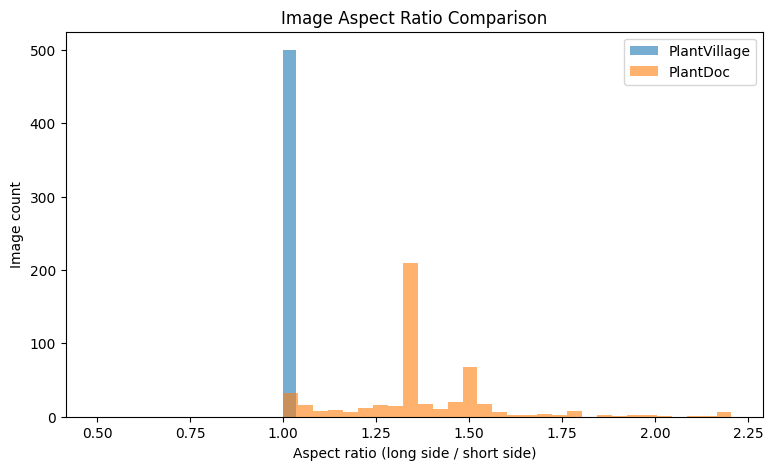

In [11]:
import pandas as pd
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

pv = pd.read_csv(ROOT / "data/splits/pv_test.csv")
pd_doc = pd.read_csv(
    ROOT / "data/splits/plantdoc_external_all.csv"
)

def get_ratios(frame, sample_size=500):
    sample = frame.sample(
        n=min(sample_size, len(frame)),
        random_state=42
    )

    ratios = []

    for path in sample["image_path"]:
        with Image.open(ROOT / path) as img:
            w, h = img.size
            ratios.append(max(w/h, h/w))

    return np.array(ratios)

pv_ratios = get_ratios(pv)
doc_ratios = get_ratios(pd_doc)

for name, ratios in [
    ("PlantVillage", pv_ratios),
    ("PlantDoc", doc_ratios)
]:
    print(f"\n{name}")
    print("样本数:", len(ratios))
    print("平均长宽比例:", round(ratios.mean(), 3))
    print("明显非正方形比例 (>1.2):",
          round(np.mean(ratios > 1.2) * 100, 2), "%")
    print("长宽差异较大比例 (>1.5):",
          round(np.mean(ratios > 1.5) * 100, 2), "%")

plt.figure(figsize=(9, 5))
plt.hist(pv_ratios, bins=30, alpha=0.6,
         label="PlantVillage")
plt.hist(doc_ratios, bins=30, alpha=0.6,
         label="PlantDoc")

plt.xlabel("Aspect ratio (long side / short side)")
plt.ylabel("Image count")
plt.title("Image Aspect Ratio Comparison")
plt.legend()
plt.show()

真实类别: tomato_bacterial_spot
原方法: tomato_early_blight (0.315)
新方法: tomato_septoria_leaf_spot (0.879)

真实类别: tomato_leaf_mold
原方法: tomato_late_blight (0.867)
新方法: tomato_septoria_leaf_spot (0.622)

真实类别: tomato_tomato_mosaic_virus
原方法: tomato_late_blight (0.432)
新方法: tomato_septoria_leaf_spot (0.684)

真实类别: tomato_healthy
原方法: tomato_late_blight (0.575)
新方法: tomato_septoria_leaf_spot (0.716)



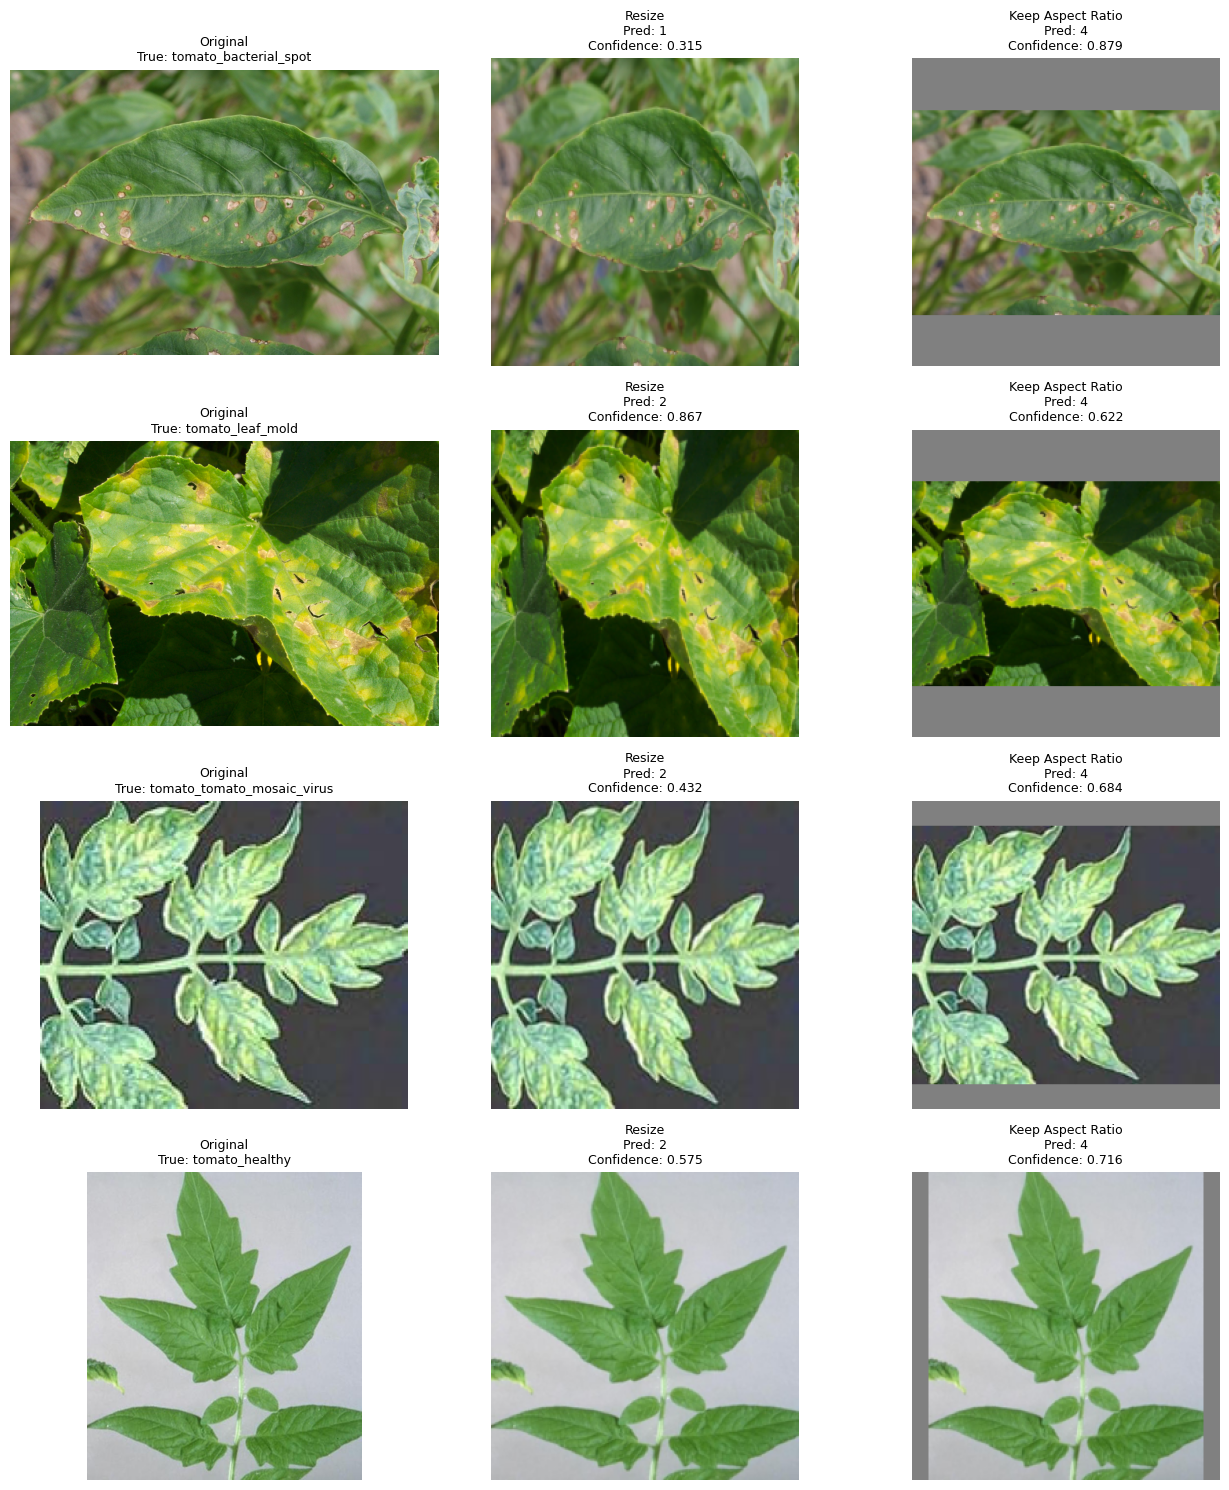

In [12]:
from PIL import Image, ImageOps
import matplotlib.pyplot as plt

# 每个重点类别选取一张误判图片
indices = [0, 4, 8, 12]

fig, axes = plt.subplots(4, 3, figsize=(13, 15))

for i, idx in enumerate(indices):

    row = selected[idx]

    with Image.open(ROOT / row["image_path"]) as f:
        original = f.convert("RGB")

    # A：原来的强制缩放方式
    stretched = original.resize(
        (224, 224),
        Image.Resampling.BILINEAR
    )

    # B：保持原始长宽比，填充至224×224
    letterboxed = ImageOps.pad(
        original,
        (224, 224),
        method=Image.Resampling.BILINEAR,
        color=(128, 128, 128)
    )

    # 原来的预测
    result_a = predict_image(
        model, original, transform,
        CLASSES, device=DEVICE
    )

    # 保持长宽比后的预测
    result_b = predict_image(
        model, letterboxed, transform,
        CLASSES, device=DEVICE
    )

    axes[i, 0].imshow(original)
    axes[i, 0].set_title(
        f"Original\nTrue: {row['true_label']}",
        fontsize=9
    )

    axes[i, 1].imshow(stretched)
    axes[i, 1].set_title(
        f"Resize\nPred: {result_a['label_index']}\n"
        f"Confidence: {result_a['confidence']:.3f}",
        fontsize=9
    )

    axes[i, 2].imshow(letterboxed)
    axes[i, 2].set_title(
        f"Keep Aspect Ratio\nPred: {result_b['label_index']}\n"
        f"Confidence: {result_b['confidence']:.3f}",
        fontsize=9
    )

    for ax in axes[i]:
        ax.axis("off")

    print(
        f"真实类别: {row['true_label']}\n"
        f"原方法: {result_a['label']} "
        f"({result_a['confidence']:.3f})\n"
        f"新方法: {result_b['label']} "
        f"({result_b['confidence']:.3f})\n"
    )

plt.tight_layout()
plt.show()

## 结论记录

- **同域测试结果：** 本实验采用 E3 阶段选定的 EfficientNet-B0 + Full + Combined 模型，在 PlantVillage 独立测试集上进行八分类评价。测试集共包含 2,259 张图像，其中正确识别 2,242 张，整体准确率达到 99.25%。各类别的错误数量较少，其中番茄斑枯病和晚疫病分别出现 7 次和 6 次误判，说明模型在 PlantVillage 标准化图像条件下具有较好的分类能力。

- **跨场景泛化表现：** 在 PlantDoc 外部数据集的 629 张图像中，模型仅正确识别 185 张，整体准确率为 29.41%，Macro-F1 为 0.1738，Macro Precision 和 Macro Recall 分别为 0.2831 和 0.2403。与 PlantVillage 同域测试相比，准确率下降约 69.84 个百分点。PlantDoc 原 train 来源与 test 来源的准确率分别为 29.53% 和 28.33%，均表现出明显的分类性能下降，说明该现象并非仅出现在单一来源子集中。

- **类别混淆与误判特征：** 根据混淆矩阵，模型在 PlantDoc 上的预测结果严重集中于早疫病、晚疫病和斑枯病，629 张图像中有 606 张被预测为上述三类，占比约 96.34%。其中叶霉病和花叶病毒病的召回率均为 0，细菌斑病、黄化曲叶病毒病和健康叶片的召回率分别仅为 1.37%、5.56% 和 4.76%。这表明模型在复杂场景下难以稳定区分不同病害特征，并存在明显的类别预测偏向。

- **泛化性能下降原因分析：** PlantVillage 与 PlantDoc 在背景复杂度、光照条件、图像分辨率、主体占比及构图方式等方面存在差异。图像长宽比抽样统计表明，PlantVillage 图像均为正方形，而 PlantDoc 的平均长宽比为 1.371，其中 85.8% 的图像长宽比超过 1.2。现有统一缩放至 224×224 的处理方式可能引入几何变形。此外，模型在错误预测时的平均最高预测概率达到 79.05%，说明其在跨场景条件下还存在明显的高置信度误判现象。上述因素可能共同影响模型表现，但其具体贡献仍需进一步验证。

- **研究结论与局限性：** 本实验表明，模型在 PlantVillage 上获得较高的同域分类准确率，并不意味着其能够直接适应真实复杂场景。尽管数据清单和标签编号检查未发现不一致，部分 PlantDoc 类别仍存在语义映射不确定性，PlantVillage 也存在部分样本来源分组不完整的问题，因此当前结果应在数据质量限制下解释。后续可围绕图像预处理、背景干扰抑制和面向复杂采集条件的鲁棒数据增强开展研究。由于 PlantDoc 已用于本阶段诊断，后续改进方法应使用独立开发验证数据进行选择，并通过新的独立外部数据检验实际泛化效果。